# 04 · Business insights (Findings mode)

> **Illustrative scenario.** The stakeholder and decision are invented: a CRM and trading team at a UK online gift supplier that plans account management each quarter. The data is real (a UK online gift retailer, 2009-2011, with many wholesale buyers, registered customers only) and contains **no marketing contact data**. "Repeat purchase" means ordering again within 90 days of a cutoff. Nothing here measures the effect of contacting anyone.

**Evidence status.** The G2 evidence gate returned **Findings**: the segments and the propensity model both rank repeat buyers above chance on a held-out test window (cutoff 2011-09-11), each with computed verdict STRONG. Every choice was frozen before the first test score; the window was scored six times in total, and an initial feasibility check had already run a prototype on it before the plan was fixed (docs/METHODOLOGY.md section 6). The propensity model's calibration check failed, so its scores are used **as a ranking only**: this notebook states no probabilities and no expected numbers of buyers.

**Sources.** Every number below is read from `outputs/metrics/results.json`, the frozen test predictions, the processed snapshots, or `assumptions.yaml`. Values computed here for the first time are descriptive views of frozen predictions and are labelled *supplementary*.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from segmentation_propensity import insights as ins
from segmentation_propensity import visualization as viz
from segmentation_propensity.evaluation import bootstrap_ci
from segmentation_propensity.utils import load_config, resolve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
viz.apply_style()
cfg = load_config(Path("..") / "config.yaml")
FIG, MET = resolve(cfg, "figures_dir"), resolve(cfg, "metrics_dir")
rng = np.random.default_rng(cfg["project"]["seed"] + 5)
NB = cfg["evaluation"]["bootstrap_resamples"]
margin = cfg["evaluation"]["strong_margin"]

res = ins.load_results(cfg)
R, st = res["by_id"], res["status"]
A = ins.load_assumptions(cfg)
with open(resolve(cfg, "segmentation_selection_json"), encoding="utf-8") as f:
    sel = json.load(f)
with open(resolve(cfg, "metrics_dir") / "data_summary.json", encoding="utf-8") as f:
    phase1 = json.load(f)

seg_ctx = res["context"]["segmentation"]
seg_names = {int(k): v for k, v in seg_ctx["names"].items()}
dev_rates = {int(k): v for k, v in seg_ctx["dev_rates"].items()}
RULE_NAMES = {0: "RFM group 1 (low)", 1: "RFM group 2 (middle)", 2: "RFM group 3 (high)"}

preds = pd.read_csv(resolve(cfg, "test_predictions_csv"))
snap = pd.read_csv(resolve(cfg, "processed_dir") / "snapshot_test.csv")
df = preds.merge(snap[["customer_id", "avg_order_value_gbp", "recency_days", "frequency_invoices", "monetary_net_gbp"]],
                 on="customer_id", how="left", validate="one_to_one")
assert df.avg_order_value_gbp.notna().all() and len(df) == R["P1"]["n"]
df["segment_name"] = df.segment.map(seg_names)
df["rule_name"] = df.rule_group.map(RULE_NAMES)
df["rank_score"] = df.p.rank(method="first")  # ranking only; the score scale is not used
print(f"Test window: {len(df):,} customers, {int(df.y.sum()):,} ordered again within 90 days")

Test window: 3,238 customers, 1,868 ordered again within 90 days


## 1. The operational segments: RFM quintile rule
The plan's decision metric (S2) compares the k-means segments with a simple RFM quintile rule built in SQL (`sql/04_rfm_rule_segments.sql`, cut points from the dev window). The k-means segments were not distinguishable from the rule (the S2 interval spans 0) and the rule is simpler to run, so the rule is the recommended operational segmentation, and the k-means segments are kept as the descriptive profile layer.

S2, k-means minus RFM rule (paired AUC): -0.005 (95% CI -0.014 to +0.004): not distinguishable from 0
Recommended segmentation recorded at G2: RFM quintile rule


,group,customers,share,repeat_rate
0,RFM group 1 (low),1100,0.340,0.354
1,RFM group 2 (middle),1071,0.331,0.555
2,RFM group 3 (high),1067,0.330,0.829


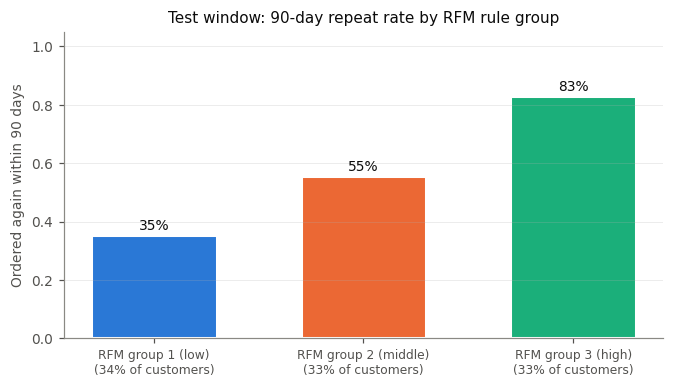

In [2]:
s2 = R["S2"]
print(f"S2, k-means minus RFM rule (paired AUC): {s2['value']:+.3f} (95% CI {s2['ci_low']:+.3f} to {s2['ci_high']:+.3f}): {ins.difference_label(s2['ci_low'], s2['ci_high'])}")
print("Recommended segmentation recorded at G2:", st["recommended_segmentation"])
rule = df.groupby("rule_group").agg(customers=("y", "size"), repeat_rate=("y", "mean")).reset_index()
rule["share"] = rule.customers / rule.customers.sum()
rule["group"] = rule.rule_group.map(RULE_NAMES)
fig = viz.plot_group_rates(rule.group, rule.share, rule.repeat_rate, "Test window: 90-day repeat rate by RFM rule group")
viz.save_figure(fig, FIG / "insight_rule_groups.png", dpi=300)
ins.save_table(rule[["group", "customers", "share", "repeat_rate"]], MET / "rule_group_rates.csv")
rule[["group", "customers", "share", "repeat_rate"]].round(3)

How the two segmentations line up on the test window (customers). The rule's groups and the k-means segments largely agree; most disagreement sits around the middle group.

In [3]:
pd.crosstab(df.segment_name, df.rule_name).loc[[seg_names[j] for j in sorted(seg_names)]]

rule_name,RFM group 1 (low),RFM group 2 (middle),RFM group 3 (high)
segment_name,,,
lapsed infrequent low-value,973,71,0
cooling regular mid-value,127,999,369
recent frequent high-value,0,1,698


## 2. The descriptive layer: k-means profiles
Median behaviour in each frozen k-means segment on the test window (features measured over the 273 days before the cutoff), with each segment's repeat rate on the dev window (when it was fitted) and on the test window.

Stability: bootstrap ARI 5th percentile 0.882 (minimum useful 0.7); dev model vs val refit ARI 0.788


,customers,median_recency_days,median_invoices,median_net_spend_gbp,test_repeat_rate,share,dev_repeat_rate
segment,,,,,,,
lapsed infrequent low-value,1044,173.0,1.0,226.81,0.350,0.322,0.194
cooling regular mid-value,1495,52.0,2.0,580.75,0.589,0.462,0.380
recent frequent high-value,699,19.0,7.0,2394.98,0.891,0.216,0.785


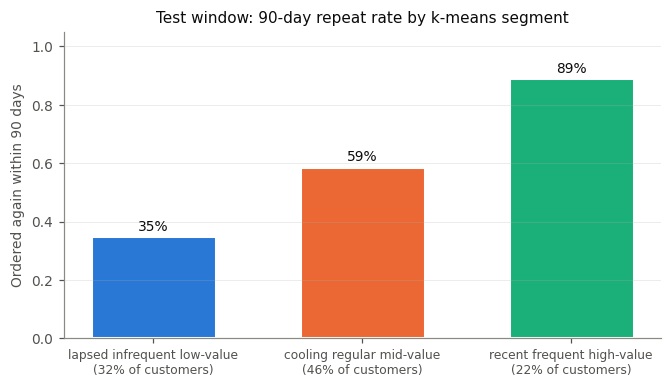

In [4]:
prof = df.groupby("segment").agg(
    customers=("y", "size"), median_recency_days=("recency_days", "median"), median_invoices=("frequency_invoices", "median"),
    median_net_spend_gbp=("monetary_net_gbp", "median"), test_repeat_rate=("y", "mean"))
prof["share"] = prof.customers / prof.customers.sum()
prof["dev_repeat_rate"] = prof.index.map(dev_rates)
prof.index = prof.index.map(seg_names)
fig = viz.plot_group_rates(prof.index, prof.share, prof.test_repeat_rate, "Test window: 90-day repeat rate by k-means segment")
viz.save_figure(fig, FIG / "insight_kmeans_segments.png")
stab = sel["stability"]
print(f"Stability: bootstrap ARI 5th percentile {stab['S3_ari_p05']:.3f} (minimum useful {stab['minimum_useful']}); dev model vs val refit ARI {stab['temporal_ari_dev_model_vs_val_refit']:.3f}")
prof.round(3)

## 3. Ranking customers
The propensity model's minimum useful AUC was set from the best segment-level AUC in an initial feasibility check on this same window. No paired test compares the model with the segments or the rule, so this section makes no claim that the model ranks better than either. The capture curve is descriptive: it shows the share of the window's repeat buyers found when contacting the best-ranked customers first. Tied customers (same segment) are ordered at random, which is how a segment-only list would behave.

*Supplementary (post hoc):* the capture curve and the share captured at the scenario's list size are computed here from the frozen test predictions.

List size 500 (A1) = top 15.4% of test customers; random order would find about 15.4% of buyers


,ranking,share_of_buyers_in_top_list,ci_low,ci_high,list_repeat_rate,rate_ci_low,rate_ci_high
0,Propensity ranking,0.252,0.243,0.259,0.940,0.910,0.962
1,RFM rule groups,0.222,0.216,0.228,0.829,0.809,0.851
2,k-means segments,0.239,0.231,0.246,0.891,0.870,0.914


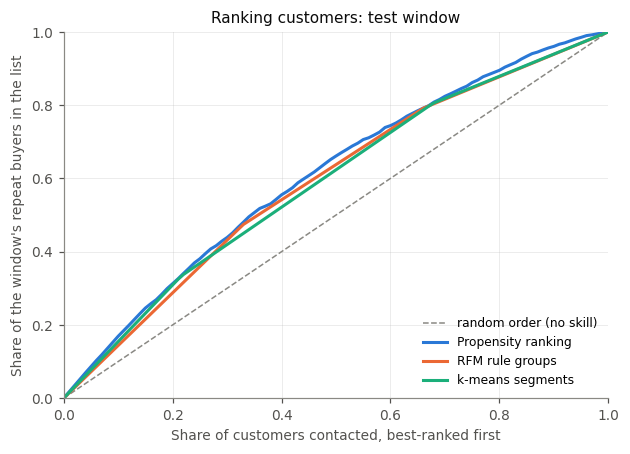

In [5]:
y = df.y.to_numpy()
seg_score = df.segment.map(dev_rates).to_numpy()
rule_score = df.rule_group.to_numpy(float)  # group order matches the rule's repeat-rate order on dev and test
fr = np.linspace(0, 1, 101)
curves = {"Propensity ranking": ins.capture_curve(y, df.rank_score.to_numpy(), fr),
          "RFM rule groups": ins.capture_curve(y, rule_score, fr),
          "k-means segments": ins.capture_curve(y, seg_score, fr)}
fig = viz.plot_capture(fr, curves)
viz.save_figure(fig, FIG / "insight_capture_curve.png")

n_list = int(A["A1"]["value"])
f_list = n_list / len(df)
cap_rows = []
for name, s in [("Propensity ranking", df.rank_score.to_numpy()), ("RFM rule groups", rule_score), ("k-means segments", seg_score)]:
    v = float(ins.capture_curve(y, s, np.array([f_list]))[0])
    lo, hi = bootstrap_ci(lambda i: float(ins.capture_curve(y[i], s[i], np.array([f_list]))[0]), len(y), rng, NB)
    # share of the list who ordered again (ties: expected value under random order)
    rate_of = lambda i: float(ins.capture_curve(y[i], s[i], np.array([f_list]))[0]) * y[i].sum() / n_list
    rlo, rhi = bootstrap_ci(rate_of, len(y), rng, NB)
    cap_rows.append({"ranking": name, "share_of_buyers_in_top_list": v, "ci_low": lo, "ci_high": hi,
                     "list_repeat_rate": v * y.sum() / n_list, "rate_ci_low": rlo, "rate_ci_high": rhi})
cap = pd.DataFrame(cap_rows)
ins.save_table(cap.assign(list_size=n_list), MET / "supplementary_list_capture.csv")
print(f"List size {n_list} (A1) = top {100 * f_list:.1f}% of test customers; random order would find about {100 * f_list:.1f}% of buyers")
cap.round(3)

### Ranking inside each segment
Within-segment AUC for the k-means segments comes from the test evaluation (`results.json`). The same view for the recommended RFM rule groups is *supplementary, post hoc* (computed here from the frozen test predictions). Confidence labels apply the G2 interval rules against chance (0.5); they are descriptive, not gate verdicts.

,segmentation,group,value,ci_low,ci_high,n,n_events,confidence
0,k-means (results.json),lapsed infrequent low-value,0.625,0.589,0.660,1044,365,Moderate
1,k-means (results.json),cooling regular mid-value,0.624,0.596,0.654,1495,880,Moderate
2,k-means (results.json),recent frequent high-value,0.750,0.699,0.798,699,623,High
3,RFM rule (supplementary),RFM group 1 (low),0.613,0.580,0.648,1100,389,Moderate
4,RFM rule (supplementary),RFM group 2 (middle),0.590,0.557,0.626,1071,594,Moderate
5,RFM rule (supplementary),RFM group 3 (high),0.742,0.705,0.778,1067,885,High


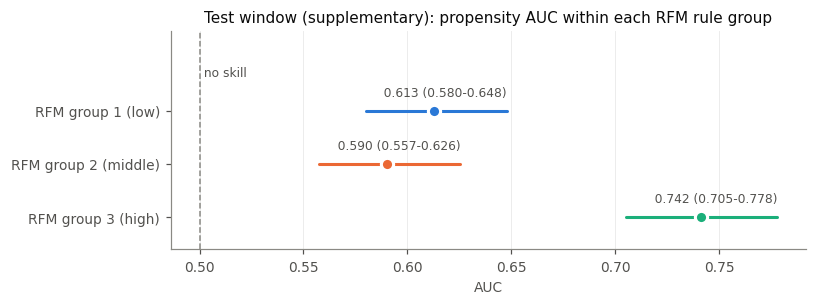

In [6]:
ws = pd.DataFrame([{"segmentation": "k-means (results.json)", "group": g, **v} for g, v in res["within_segment_propensity_auc"].items()])
wr = ins.within_group_auc(df, "rule_name", "rank_score", rng, NB).rename(columns={"rule_name": "group"})
wr["segmentation"] = "RFM rule (supplementary)"
within = pd.concat([ws, wr[ws.columns]], ignore_index=True)
within["confidence"] = [ins.confidence_label(r.value, r.ci_low, 0.5, margin) for r in within.itertuples()]
ins.save_table(within, MET / "supplementary_within_group_auc.csv")
fig = viz.plot_intervals(wr.assign(label=wr.group), "Test window (supplementary): propensity AUC within each RFM rule group", "AUC",
                         references={"no skill": 0.5}, colors=viz.SERIES[:3])
viz.save_figure(fig, FIG / "insight_within_rule_group.png")
within[["segmentation", "group", "value", "ci_low", "ci_high", "n", "n_events", "confidence"]].round(3)

## 4. Insights
Each insight lists its evidence and its basis: the test evaluation in `results.json`, or a post hoc, descriptive view of the frozen test predictions. The verdict column holds only a computed verdict from `results.json`; rows without one carry no strength label. I4 is a post hoc list comparison, not a paired test, so it does not show that the model ranks better than the rule; the within-segment AUCs in section 3 describe how well the model orders customers inside each group.

In [7]:
s1, rr, rc, s4, p1 = R["S1"], R["S1_ref_rule"], R["S1_ref_recency"], R["S4"], R["P1"]
rate = res["segment_test_rates"]
lo_seg, hi_seg = seg_names[0], seg_names[max(seg_names)]
rule_within = within.query("segmentation != 'k-means (results.json)'").set_index("group")
top_rule, mid_rule = rule_within.loc[RULE_NAMES[2]], rule_within.loc[RULE_NAMES[1]]
cap_p = cap.set_index("ranking").loc["Propensity ranking"]; cap_r = cap.set_index("ranking").loc["RFM rule groups"]
fmt = lambda r: f"{r['value']:.3f} (95% CI {r['ci_low']:.3f}-{r['ci_high']:.3f})"
TEST, POST = "test evaluation (results.json)", "post hoc, descriptive (frozen test predictions)"
# verdict: only the computed verdict from results.json; blank where none exists
insights = pd.DataFrame([
    {"id": "I1", "insight": f"Three customer groups separate who orders again on a later, held-out quarter: repeat rates run from {100 * rate[lo_seg]:.0f}% ({lo_seg}) to {100 * rate[hi_seg]:.0f}% ({hi_seg}).",
     "evidence": f"S1 segment-score AUC {fmt(s1)}; stability ARI p05 {stab['S3_ari_p05']:.3f}",
     "basis": TEST, "verdict": f"S1 {s1['verdict']}"},
    {"id": "I2", "insight": "A simple RFM quintile rule is not distinguishable from the k-means segments and is simpler to run, so the rule is the practical choice for operations.",
     "evidence": f"S2 k-means minus rule {s2['value']:+.3f} (95% CI {s2['ci_low']:+.3f} to {s2['ci_high']:+.3f}), {ins.difference_label(s2['ci_low'], s2['ci_high'])}; rule AUC {fmt(rr)}",
     "basis": TEST, "verdict": ""},
    {"id": "I3", "insight": "Segments carry information beyond how recently a customer last ordered, though the gain is small.",
     "evidence": f"S4 recency + segments minus recency {s4['value']:+.3f} (95% CI {s4['ci_low']:+.3f} to {s4['ci_high']:+.3f}), {ins.difference_label(s4['ci_low'], s4['ci_high'])}; recency-only AUC {fmt(rc)}",
     "basis": TEST, "verdict": ""},
    {"id": "I4", "insight": f"Post hoc, descriptive: {100 * cap_p.list_repeat_rate:.0f}% of the model's top {n_list} ordered again, and {100 * cap_r.list_repeat_rate:.0f}% of {n_list} customers picked at random from the top RFM group. This is not a paired test and does not show that the model ranks better than the rule.",
     "evidence": f"list repeat rates {cap_p.list_repeat_rate:.3f} ({cap_p.rate_ci_low:.3f}-{cap_p.rate_ci_high:.3f}) and {cap_r.list_repeat_rate:.3f} ({cap_r.rate_ci_low:.3f}-{cap_r.rate_ci_high:.3f})",
     "basis": POST, "verdict": ""},
    {"id": "I5", "insight": "Inside each RFM group the model still orders customers above chance, but less well in the low and middle groups. Scores order customers; they are not probabilities.",
     "evidence": f"within top RFM group {top_rule['value']:.3f} ({top_rule['ci_low']:.3f}-{top_rule['ci_high']:.3f}); middle group {mid_rule['value']:.3f} ({mid_rule['ci_low']:.3f}-{mid_rule['ci_high']:.3f}); calibration slope {res['calibration']['slope']:.2f} fails P2 (results.json)",
     "basis": POST, "verdict": ""},
])
ins.save_table(insights, MET / "insights.csv")
insights

,id,insight,evidence,basis,verdict
0,I1,"Three customer groups separate who orders again on a later, held-out quarter: repeat rates run from 35% (lapsed infr...",S1 segment-score AUC 0.712 (95% CI 0.694-0.727); stability ARI p05 0.882,test evaluation (results.json),S1 STRONG
1,I2,"A simple RFM quintile rule is not distinguishable from the k-means segments and is simpler to run, so the rule is th...","S2 k-means minus rule -0.005 (95% CI -0.014 to +0.004), not distinguishable from 0; rule AUC 0.717 (95% CI 0.700-0.733)",test evaluation (results.json),
2,I3,"Segments carry information beyond how recently a customer last ordered, though the gain is small.","S4 recency + segments minus recency +0.033 (95% CI +0.027 to +0.040), positive (CI excludes 0); recency-only AUC 0.6...",test evaluation (results.json),
3,I4,"Post hoc, descriptive: 94% of the model's top 500 ordered again, and 83% of 500 customers picked at random from the ...",list repeat rates 0.940 (0.910-0.962) and 0.829 (0.809-0.851),"post hoc, descriptive (frozen test predictions)",
4,I5,"Inside each RFM group the model still orders customers above chance, but less well in the low and middle groups. Sco...",within top RFM group 0.742 (0.705-0.778); middle group 0.590 (0.557-0.626); calibration slope 1.22 fails P2 (results...,"post hoc, descriptive (frozen test predictions)",


## 5. Recommendations
1. **Use the RFM quintile rule (3 groups, dev-window cut points) as the operational segmentation.** It is not distinguishable from k-means on the test window (the S2 interval spans 0; I2) and is simpler to run: a few lines of transparent SQL.
2. **Use the k-means segments as the descriptive layer** for planning conversations: they name recognisable behaviours (lapsed, cooling, recent and frequent) and are stable under resampling. They drift over time (see the temporal agreement above), so refit and re-check them each quarter rather than treating the labels as permanent.
3. **Order customers within each RFM group by the model's rank, never by its score value.** Within-group AUCs are above chance in every group (descriptive; I5); the scores are miscalibrated, so they must not be read as probabilities or summed into expected buyer counts.
4. **Measure the effect of contact before scaling it.** The data has no contact records, so it cannot say whether contacting anyone changes what they do. A randomised holdout (contact a random half of each list, compare 90-day order rates) is the cheapest way to find out.

## 6. Illustrative scenario: what a 500-customer contact list looks like

> **Illustrative scenario: unsourced assumptions.** List size, contact cost and margin rate are assumptions A1-A3 from `assumptions.yaml`, not facts about any business. The incremental effect of contact (A4) is **not estimable** from this data. The table shows only (a) what the listed customers did in the test window without any contact programme, and (b) how many *extra* orders the list would need to cover its cost. It does **not** estimate revenue from contact, and no model score is used as a probability.

In [8]:
for a in ["A1", "A2", "A3", "A4"]:
    print(f"{a}: {A[a]['description']} = {A[a]['value']} ({A[a]['source']})")
cost, mrate = float(A["A2"]["value"]), float(A["A3"]["value"])
lists = [
    ("Top by model rank, all customers", ins.scenario_list(df, n_list, "rank_score")),
    ("Top by model rank, RFM group 2 (middle)", ins.scenario_list(df, n_list, "rank_score", "rule_group", 1)),
    ("Top by model rank, RFM group 1 (low)", ins.scenario_list(df, n_list, "rank_score", "rule_group", 0)),
]
scen = pd.DataFrame([ins.summarise_list(l, name, cost, mrate) for name, l in lists])
scen["top_list_rule_groups"] = [l.rule_name.value_counts().to_dict() for _, l in lists]
ins.save_table(scen.drop(columns="top_list_rule_groups"), MET / "illustrative_scenario.csv")
scen.round(1)

A1: Number of customers the team can contact proactively per quarter = 500 (unsourced assumption)
A2: Cost per proactive contact (staff time and materials), GBP = 2.0 (unsourced assumption)
A3: Gross margin rate on merchandise value = 0.35 (unsourced assumption)
A4: Incremental effect of contacting a customer on their chance of ordering = None (NOT ESTIMABLE from this data (no contact or treatment records))


,list,customers,ordered_in_test_window,did_not_order,median_past_order_value_gbp,contact_cost_gbp,incremental_value_needed_gbp,incremental_orders_needed,top_list_rule_groups
0,"Top by model rank, all customers",500,470,30,348.3,1000.0,2857.1,8.2,{'RFM group 3 (high)': 500}
1,"Top by model rank, RFM group 2 (middle)",500,316,184,299.5,1000.0,2857.1,9.5,{'RFM group 2 (middle)': 500}
2,"Top by model rank, RFM group 1 (low)",500,217,283,252.2,1000.0,2857.1,11.3,{'RFM group 1 (low)': 500}


In [9]:
t = scen.iloc[0]
print(f"- A list built from the model rank alone is all high-group customers; {int(t.ordered_in_test_window)} of {int(t.customers)} ordered in the window with no programme, "
      f"so at most {int(t.did_not_order)} could add an order. It needs about {t.incremental_orders_needed:.0f} extra orders to cover £{t.contact_cost_gbp:,.0f}.")
for _, r in scen.iloc[1:].iterrows():
    print(f"- {r.list}: {int(r.ordered_in_test_window)} of {int(r.customers)} ordered anyway; {int(r.did_not_order)} did not; break-even needs about {r.incremental_orders_needed:.0f} extra orders.")
print("- Whether any list reaches break-even depends on A4, which this data cannot estimate. The holdout test in recommendation 4 answers it.")

- A list built from the model rank alone is all high-group customers; 470 of 500 ordered in the window with no programme, so at most 30 could add an order. It needs about 8 extra orders to cover £1,000.
- Top by model rank, RFM group 2 (middle): 316 of 500 ordered anyway; 184 did not; break-even needs about 10 extra orders.
- Top by model rank, RFM group 1 (low): 217 of 500 ordered anyway; 283 did not; break-even needs about 11 extra orders.
- Whether any list reaches break-even depends on A4, which this data cannot estimate. The holdout test in recommendation 4 answers it.


## 7. Limitations

In [10]:
miss = next(r for r in phase1["cleaning_log"] if r["status"] == "missing_customer_id")
lims = [
    f"Calibration fails (P2: slope {res['calibration']['slope']:.2f}, mean score {res['calibration']['calibration_in_the_large']:+.3f} above the observed rate). The test label window is the September-December peak. Scores are rankings only.",
    f"Segments are reasonably, not fully, stable over time: the dev model and a val-window refit agree at ARI {stab['temporal_ari_dev_model_vs_val_refit']:.3f}.",
    "No contact, campaign or treatment data: nothing here is a response rate or a causal effect, and the incremental value of contact (A4) is unknown.",
    f"Registered customers only: {100 * miss['share_of_lines']:.1f}% of raw lines have no Customer ID and are excluded (notebook 01 gives the share of sales value).",
    "One retailer, 2009-2011, a UK gift trade with many wholesale buyers. The segment definitions and rates may not transfer to other businesses or periods.",
    "The test window was scored six times in total (the first run, then five re-runs to check a record-merging fix and remove run-to-run non-determinism); no modelling choice changed and the final numbers equal the first run. Before the plan was fixed, an initial feasibility check ran a prototype on the same window, which informed the minimum-useful targets and the training-window design (see docs/METHODOLOGY.md, section 6).",
]
for l in lims:
    print("-", l)

- Calibration fails (P2: slope 1.22, mean score +0.043 above the observed rate). The test label window is the September-December peak. Scores are rankings only.
- Segments are reasonably, not fully, stable over time: the dev model and a val-window refit agree at ARI 0.788.
- No contact, campaign or treatment data: nothing here is a response rate or a causal effect, and the incremental value of contact (A4) is unknown.
- Registered customers only: 22.8% of raw lines have no Customer ID and are excluded (notebook 01 gives the share of sales value).
- One retailer, 2009-2011, a UK gift trade with many wholesale buyers. The segment definitions and rates may not transfer to other businesses or periods.
- The test window was scored six times in total (the first run, then five re-runs to check a record-merging fix and remove run-to-run non-determinism); no modelling choice changed and the final numbers equal the first run. Before the plan was fixed, an initial feasibility check ran a prototyp

## 8. Executive summary
Generated from the results above so the numbers cannot drift from `results.json`.

In [11]:
summary = f'''Customers of a UK online gift retailer fall into three groups that separate who orders again within 90 days.
On a later, held-out quarter the groups' repeat rates ran from {100 * rate[lo_seg]:.0f}% to {100 * rate[hi_seg]:.0f}%, and ranking customers by group
scored above chance (AUC {s1['value']:.2f}, 95% CI {s1['ci_low']:.2f}-{s1['ci_high']:.2f}; verdict {s1['verdict']}). A simple RFM scoring rule was not distinguishable from the
clustering and is simpler to run, so it is the recommended way to segment in practice, with the clusters kept as plain-language profiles.
A customer-level model ranks repeat buyers with AUC {p1['value']:.2f} (95% CI {p1['ci_low']:.2f}-{p1['ci_high']:.2f}; verdict {p1['verdict']}) and still ranks above chance inside
each segment, so it is useful for ordering customers inside each group; its scores are not reliable probabilities. The data has no contact records, so it cannot show
whether contacting customers changes what they do; a randomised holdout test is the next step before any spend.'''
print(summary)

Customers of a UK online gift retailer fall into three groups that separate who orders again within 90 days.
On a later, held-out quarter the groups' repeat rates ran from 35% to 89%, and ranking customers by group
scored above chance (AUC 0.71, 95% CI 0.69-0.73; verdict STRONG). A simple RFM scoring rule was not distinguishable from the
clustering and is simpler to run, so it is the recommended way to segment in practice, with the clusters kept as plain-language profiles.
A customer-level model ranks repeat buyers with AUC 0.76 (95% CI 0.74-0.77; verdict STRONG) and still ranks above chance inside
each segment, so it is useful for ordering customers inside each group; its scores are not reliable probabilities. The data has no contact records, so it cannot show
whether contacting customers changes what they do; a randomised holdout test is the next step before any spend.
